# Air Quality Outlier & Trend Mining

Khai phá dữ liệu chất lượng không khí (UCI Air Quality): **tiền xử lý chuỗi thời gian → phát hiện đỉnh ô nhiễm bất thường → khai phá mẫu tuần tự theo giờ/mùa → phân cụm hồ sơ ô nhiễm theo ngày**.

Quy ước biểu đồ: tiêu đề in đậm nêu phát hiện, dòng phụ hướng dẫn cách đọc; mỗi chất ô nhiễm và mỗi cụm giữ một màu cố định xuyên suốt notebook. Mọi biểu đồ được lưu vào `reports/figures/`.

## 0. Thiết lập

In [1]:
import io
import json
import os
import urllib.request
import warnings
import zipfile
from pathlib import Path

# Tắt cảnh báo môi trường (pyarrow, số lõi CPU) trước khi import thư viện để output gọn.
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
# loky chỉ bỏ bước dò lõi vật lý (in traceback trên Windows không có wmic) khi giới hạn < số lõi logic.
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(max(1, (os.cpu_count() or 2) - 1)))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.dates import DateFormatter
from prefixspan import PrefixSpan
from scipy.cluster.hierarchy import dendrogram, linkage, set_link_color_palette
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, silhouette_score)
from sklearn.neighbors import NearestNeighbors
from statsmodels.tsa.seasonal import MSTL

SEED = 42
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
CSV = DATA / "AirQualityUCI.csv"
URL = "https://archive.ics.uci.edu/static/public/360/air+quality.zip"

if not CSV.exists():
    DATA.mkdir(exist_ok=True)
    with urllib.request.urlopen(URL, timeout=120) as resp:
        zipfile.ZipFile(io.BytesIO(resp.read())).extract("AirQualityUCI.csv", DATA)

# Bảng màu categorical cố định (đã kiểm tra CVD); độ tương phản thấp của slot 3-4 được bù bằng nhãn/legend + bảng CSV.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED, GRID, NEUTRAL = "#0b0b0b", "#52514e", "#e4e3df", "#b9b8b2"
DIVERGING = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#efeeeb", "#eb6834"])
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": NEUTRAL, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "legend.frameon": False, "lines.linewidth": 2,
})
SUMMARY: dict = {}


def finish(fig, name: str, title: str, subtitle: str) -> None:
    # Tiêu đề nêu phát hiện + dòng phụ cách đọc, lưu 150 dpi.
    h = fig.get_figheight()  # khoảng cách tính theo inch để không đè nhau ở hình thấp
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.75 / h))
    fig.text(0.01, 1 - 0.08 / h, title, ha="left", va="top", fontsize=13, fontweight="bold", color=INK)
    fig.text(0.01, 1 - 0.38 / h, subtitle, ha="left", va="top", fontsize=9.5, color=MUTED)
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")
    plt.show()

## 1. Đọc dữ liệu và khám phá (EDA)

File CSV dùng `;` phân tách và `,` thập phân, giá trị thiếu được mã hóa là **-200**, cuối file có cột/dòng rỗng. Dữ liệu là chuỗi theo giờ từ **một thiết bị cảm biến đa kênh** đặt tại một con đường ở một thành phố Ý.

In [2]:
df = (pd.read_csv(CSV, sep=";", decimal=",")
        .dropna(axis=1, how="all").dropna(axis=0, how="all"))
df.index = pd.to_datetime(df.pop("Date") + " " + df.pop("Time"), format="%d/%m/%Y %H.%M.%S")
df = df.replace(-200, np.nan)
n_before = len(df)
df = df.asfreq("h")  # lưới giờ liên tục: mốc giờ bị thiếu thành NaN
assert df.index.is_unique and df.index.is_monotonic_increasing
print(f"{len(df):,} giờ ({n_before:,} dòng gốc), {df.index.min()} → {df.index.max()}, {df.shape[1]} cột")
SUMMARY["n_hours"] = len(df)
SUMMARY["period"] = f"{df.index.min():%d/%m/%Y} – {df.index.max():%d/%m/%Y}"
df.describe().T.round(2)

9,357 giờ (9,357 dòng gốc), 2004-03-10 18:00:00 → 2005-04-04 14:00:00, 13 cột


,count,mean,std,min,25%,50%,75%,max
CO(GT),7674.0,2.15,1.45,0.10,1.10,1.8,2.90,11.90
PT08.S1(CO),8991.0,1099.83,217.08,647.00,937.00,1063.0,1231.00,2040.00
NMHC(GT),914.0,218.81,204.46,7.00,67.00,150.0,297.00,1189.00
C6H6(GT),8991.0,10.08,7.45,0.10,4.40,8.2,14.00,63.70
PT08.S2(NMHC),8991.0,939.15,266.83,383.00,734.50,909.0,1116.00,2214.00
NOx(GT),7718.0,246.90,212.98,2.00,98.00,180.0,326.00,1479.00
PT08.S3(NOx),8991.0,835.49,256.82,322.00,658.00,806.0,969.50,2683.00
NO2(GT),7715.0,113.09,48.37,2.00,78.00,109.0,142.00,340.00
PT08.S4(NO2),8991.0,1456.26,346.21,551.00,1227.00,1463.0,1674.00,2775.00
PT08.S5(O3),8991.0,1022.91,398.48,221.00,731.50,963.0,1273.50,2523.00


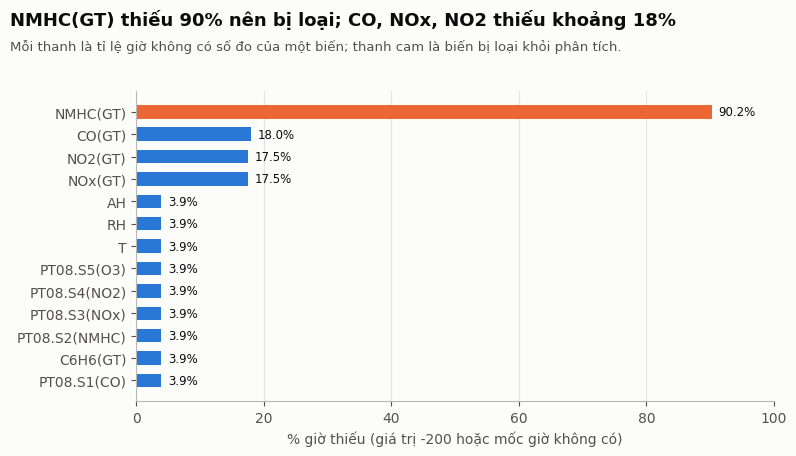

In [3]:
miss = (df.isna().mean() * 100).sort_values()
SUMMARY["missing_pct"] = miss.round(1).to_dict()
fig, ax = plt.subplots(figsize=(8, 4.6))
colors = [PALETTE[1] if v > 50 else PALETTE[0] for v in miss]
ax.barh(miss.index, miss.values, color=colors, height=0.6)
for y, v in enumerate(miss.values):
    ax.text(v + 1, y, f"{v:.1f}%", va="center", fontsize=8.5, color=INK)
ax.set_xlabel("% giờ thiếu (giá trị -200 hoặc mốc giờ không có)")
ax.set_xlim(0, 100)
ax.grid(axis="y", visible=False)
finish(fig, "01_missing.png",
       f"NMHC(GT) thiếu {miss['NMHC(GT)']:.0f}% nên bị loại; CO, NOx, NO2 thiếu khoảng {miss['CO(GT)']:.0f}%",
       "Mỗi thanh là tỉ lệ giờ không có số đo của một biến; thanh cam là biến bị loại khỏi phân tích.")

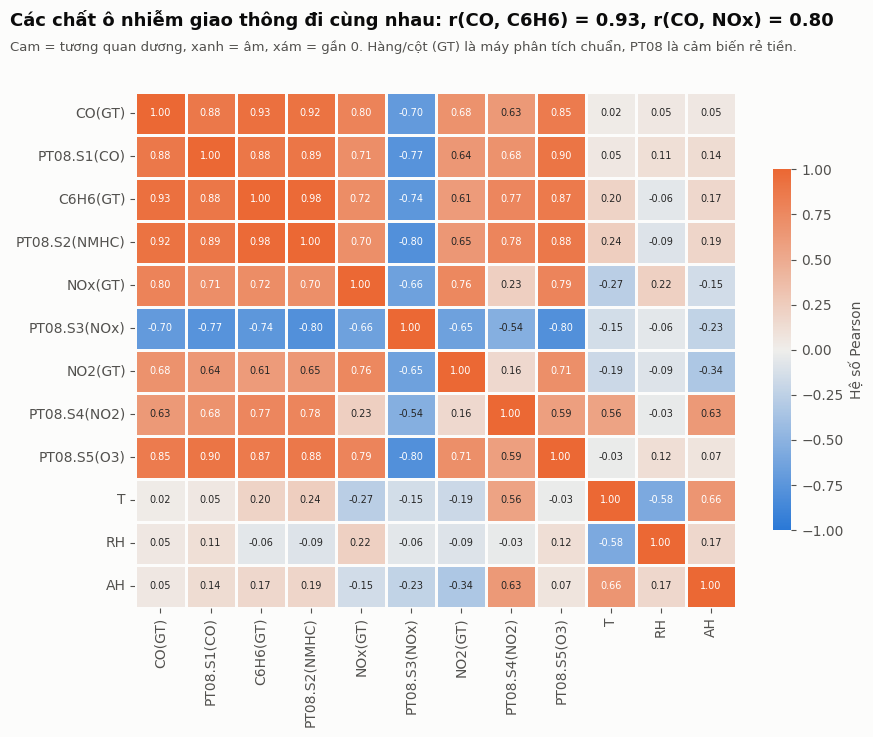

In [4]:
cols_corr = [c for c in df.columns if c != "NMHC(GT)"]
corr = df[cols_corr].corr()
fig, ax = plt.subplots(figsize=(9, 7.4))
sns.heatmap(corr, cmap=DIVERGING, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7},
            linewidths=1, linecolor="#fcfcfb", cbar_kws={"shrink": 0.7, "label": "Hệ số Pearson"}, ax=ax)
ax.grid(False)
r_co_c6 = corr.loc["CO(GT)", "C6H6(GT)"]
r_co_nox = corr.loc["CO(GT)", "NOx(GT)"]
finish(fig, "02_corr.png",
       f"Các chất ô nhiễm giao thông đi cùng nhau: r(CO, C6H6) = {r_co_c6:.2f}, r(CO, NOx) = {r_co_nox:.2f}",
       "Cam = tương quan dương, xanh = âm, xám = gần 0. Hàng/cột (GT) là máy phân tích chuẩn, PT08 là cảm biến rẻ tiền.")

## 2. Tiền xử lý chuỗi thời gian

Phân tích tập trung vào 4 chất ô nhiễm đo bằng máy chuẩn — **CO, NOx, NO2, C6H6** (đơn vị mg/m³ hoặc µg/m³) — và 3 biến khí tượng T, RH, AH.

Quy tắc xử lý:
1. **Khoảng trống ngắn (≤ 6 giờ)** → nội suy tuyến tính theo thời gian. Chỉ lấp các khoảng trống có tổng độ dài ≤ 6 giờ; không lấp “một phần” khoảng trống dài.
2. **Khử nhiễu** → trung vị trượt cửa sổ 3 giờ (giữ đỉnh thật kéo dài ≥ 2 giờ, loại gai 1 điểm do cảm biến).
3. **Khoảng trống dài (> 6 giờ)** → giữ là NaN cho mọi phân tích trên dữ liệu thật. Riêng bước phân rã MSTL cần chuỗi liên tục nên tạm lấp bằng trung vị cùng (tháng, thứ, giờ); các điểm này **không bao giờ** được gắn nhãn bất thường hay đưa vào khai phá mẫu/phân cụm.

In [5]:
POLL = ["CO(GT)", "NOx(GT)", "NO2(GT)", "C6H6(GT)"]
MET = ["T", "RH", "AH"]
PCOLOR = dict(zip(POLL, PALETTE))
UNIT = {"CO(GT)": "mg/m³", "NOx(GT)": "ppb", "NO2(GT)": "µg/m³", "C6H6(GT)": "µg/m³"}
MAX_GAP = 6


def short_gap_mask(s: pd.Series, max_len: int) -> pd.Series:
    # True tại các NaN thuộc khoảng trống liên tiếp dài <= max_len.
    na = s.isna()
    run_id = (na != na.shift()).cumsum()
    run_len = na.groupby(run_id).transform("sum")
    return na & (run_len <= max_len)


_t = pd.Series([1, np.nan, 3, np.nan, np.nan, np.nan, 7.0])
assert short_gap_mask(_t, 2).tolist() == [False, True, False, False, False, False, False]

base = df[POLL + MET]
interp = base.copy()
for c in base:
    interp[c] = base[c].mask(short_gap_mask(base[c], MAX_GAP), base[c].interpolate(method="time"))
smooth = interp.rolling(3, center=True, min_periods=1).median().where(interp.notna())
observed = interp.notna()  # số đo thật hoặc nội suy ngắn

idx = smooth.index
filled = smooth.fillna(smooth.groupby([idx.month, idx.dayofweek, idx.hour]).transform("median"))
filled = filled.fillna(smooth.groupby([idx.dayofweek, idx.hour]).transform("median"))
assert filled.notna().all().all()
assert (smooth.notna() == observed).all().all()

prep = pd.DataFrame({
    "% thiếu gốc": base.isna().mean() * 100,
    "% nội suy ngắn": (interp.notna() & base.isna()).mean() * 100,
    "% còn thiếu (khoảng dài)": interp.isna().mean() * 100,
}).round(1)
SUMMARY["preprocess"] = prep.to_dict(orient="index")
prep

,% thiếu gốc,% nội suy ngắn,% còn thiếu (khoảng dài)
CO(GT),18.0,2.0,16.0
NOx(GT),17.5,3.5,14.0
NO2(GT),17.5,3.5,14.1
C6H6(GT),3.9,0.2,3.8
T,3.9,0.2,3.8
RH,3.9,0.2,3.8
AH,3.9,0.2,3.8


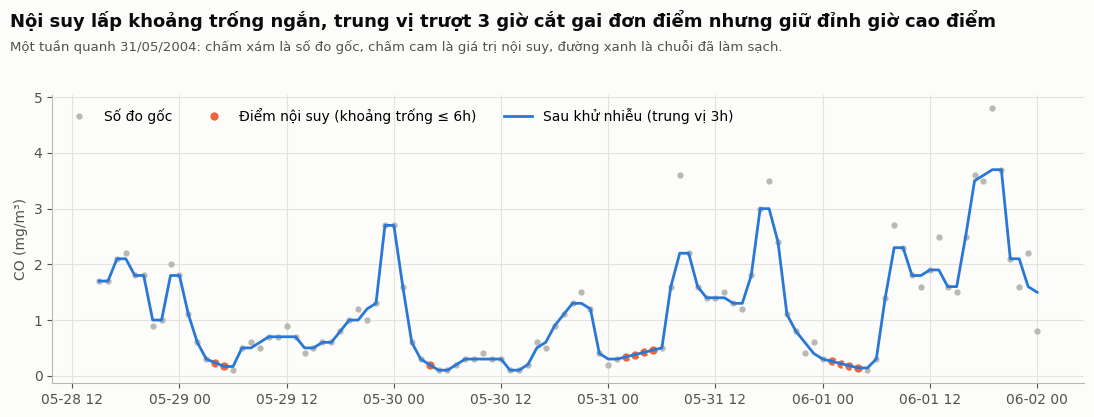

In [6]:
c = "CO(GT)"
short = short_gap_mask(base[c], MAX_GAP)
centre = short[short].index[len(short[short]) // 3]
win = slice(centre - pd.Timedelta(days=3), centre + pd.Timedelta(days=3))
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(base.loc[win, c].index, base.loc[win, c], "o", ms=3.5, color=NEUTRAL, label="Số đo gốc")
filled_pts = interp.loc[win, c][short.loc[win]]
ax.plot(filled_pts.index, filled_pts, "o", ms=8, mfc=PALETTE[1], mec="#fcfcfb", mew=2, label="Điểm nội suy (khoảng trống ≤ 6h)")
ax.plot(smooth.loc[win, c].index, smooth.loc[win, c], color=PALETTE[0], label="Sau khử nhiễu (trung vị 3h)")
ax.set_ylabel(f"CO ({UNIT[c]})")
ax.legend(loc="upper left", ncol=3)
finish(fig, "03_preprocess.png",
       "Nội suy lấp khoảng trống ngắn, trung vị trượt 3 giờ cắt gai đơn điểm nhưng giữ đỉnh giờ cao điểm",
       f"Một tuần quanh {centre:%d/%m/%Y}: chấm xám là số đo gốc, chấm cam là giá trị nội suy, đường xanh là chuỗi đã làm sạch.")

## 3. Phân rã xu hướng và mùa vụ (MSTL)

Mỗi chất được phân rã thành **xu hướng + mùa vụ ngày (24h) + mùa vụ tuần (168h) + phần dư** bằng MSTL (robust). Phân rã trên thang `log1p` vì biên độ dao động tăng theo mức nền (mùa đông dao động lớn hơn mùa hè) — trên thang log, phần dư là sai lệch **tương đối** nên ngưỡng bất thường dùng chung được cho cả năm.

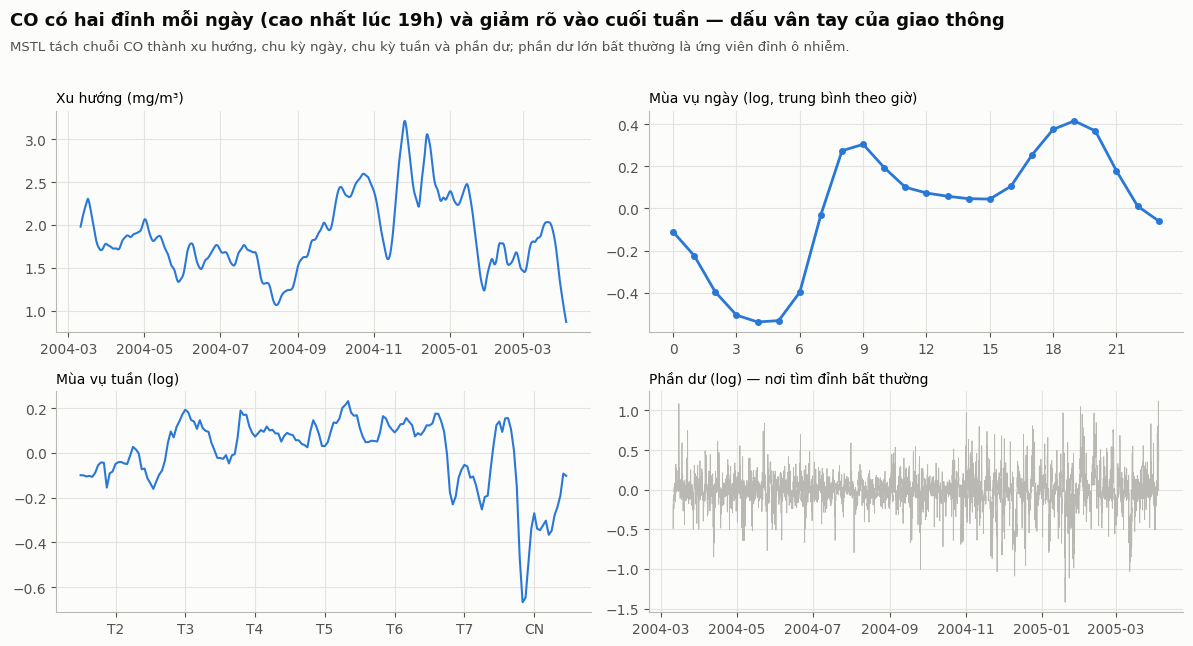

In [7]:
LOG = np.log1p(filled[POLL])
dec = {c: MSTL(LOG[c], periods=(24, 168), stl_kwargs={"robust": True}).fit() for c in POLL}

c = "CO(GT)"
d = dec[c]
fig, axes = plt.subplots(2, 2, figsize=(12, 6.5))
axes[0, 0].plot(d.trend.index, np.expm1(d.trend), color=PALETTE[0], lw=1.5)
axes[0, 0].set_title("Xu hướng (mg/m³)", loc="left", fontsize=10)
s24 = d.seasonal["seasonal_24"].groupby(d.seasonal.index.hour).mean()
axes[0, 1].plot(s24.index, s24.values, color=PALETTE[0], marker="o", ms=4)
axes[0, 1].set_title("Mùa vụ ngày (log, trung bình theo giờ)", loc="left", fontsize=10)
axes[0, 1].set_xticks(range(0, 24, 3))
how = d.seasonal.index.dayofweek * 24 + d.seasonal.index.hour
s168 = d.seasonal["seasonal_168"].groupby(how).mean()
axes[1, 0].plot(s168.index, s168.values, color=PALETTE[0], lw=1.5)
axes[1, 0].set_xticks(range(12, 168, 24), ["T2", "T3", "T4", "T5", "T6", "T7", "CN"])
axes[1, 0].set_title("Mùa vụ tuần (log)", loc="left", fontsize=10)
axes[1, 1].plot(d.resid.index, d.resid, color=NEUTRAL, lw=0.6)
axes[1, 1].set_title("Phần dư (log) — nơi tìm đỉnh bất thường", loc="left", fontsize=10)
peak_h = int(s24.idxmax())
SUMMARY["co_peak_hour"] = peak_h
finish(fig, "04_stl_co.png",
       f"CO có hai đỉnh mỗi ngày (cao nhất lúc {peak_h}h) và giảm rõ vào cuối tuần — dấu vân tay của giao thông",
       "MSTL tách chuỗi CO thành xu hướng, chu kỳ ngày, chu kỳ tuần và phần dư; phần dư lớn bất thường là ứng viên đỉnh ô nhiễm.")

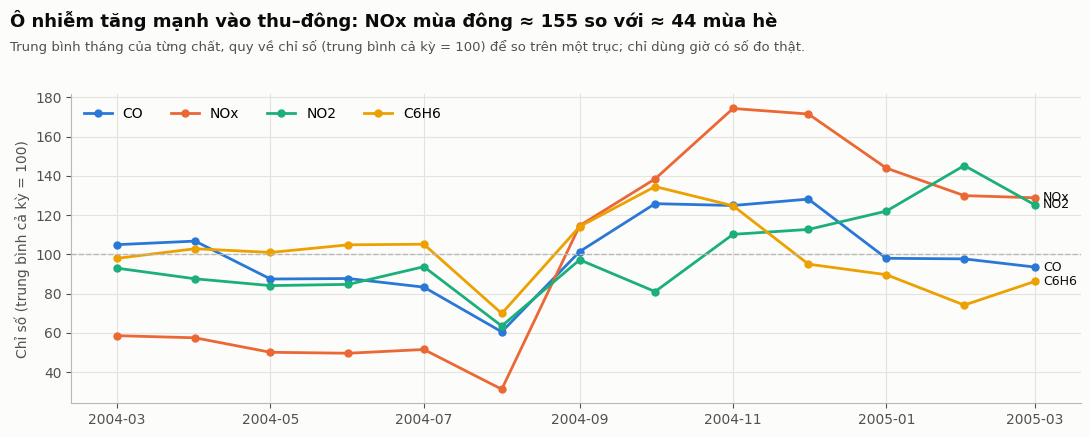

In [8]:
monthly = smooth[POLL].where(observed[POLL]).resample("MS").mean()
monthly = monthly[monthly.index < "2005-04-01"]  # tháng 4/2005 chỉ có vài ngày
indexed = monthly / monthly.mean() * 100
fig, ax = plt.subplots(figsize=(11, 4.4))
for c in POLL:
    ax.plot(indexed.index, indexed[c], color=PCOLOR[c], marker="o", ms=5, label=c.replace("(GT)", ""))
    ax.annotate(c.replace("(GT)", ""), (indexed.index[-1], indexed[c].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=9, color=INK)
ax.axhline(100, color=NEUTRAL, lw=1, ls="--")
ax.set_ylabel("Chỉ số (trung bình cả kỳ = 100)")
ax.legend(loc="upper left", ncol=4)
winter = indexed.loc[indexed.index.month.isin([11, 12, 1, 2])].mean()
summer = indexed.loc[indexed.index.month.isin([6, 7, 8])].mean()
SUMMARY["winter_vs_summer_index"] = {c: [round(summer[c]), round(winter[c])] for c in POLL}
finish(fig, "05_monthly_trend.png",
       f"Ô nhiễm tăng mạnh vào thu–đông: NOx mùa đông ≈ {winter['NOx(GT)']:.0f} so với ≈ {summer['NOx(GT)']:.0f} mùa hè",
       "Trung bình tháng của từng chất, quy về chỉ số (trung bình cả kỳ = 100) để so trên một trục; chỉ dùng giờ có số đo thật.")

## 4. Phát hiện đỉnh ô nhiễm bất thường (đơn biến)

Đỉnh ô nhiễm = giờ thỏa đồng thời:
1. phần dư MSTL vượt **robust z-score > 3,5** (z = 0,6745·(r − trung vị)/MAD, ngưỡng của Iglewicz & Hoaglin), chỉ chiều dương;
2. nồng độ **cao hơn trung vị** của chính chất đó — loại các “đỉnh tương đối” lúc nửa đêm khi nồng độ rất thấp (trên thang log, 0,5 → 1 mg/m³ cũng là phần dư lớn);
3. là giờ có số đo thật và không nằm trong 7 ngày đầu/cuối chuỗi (biên của MSTL).

**Đối chứng (baseline):** z-score toàn cục trên chuỗi đã làm sạch (> 3σ). Baseline này chỉ tìm “giờ ô nhiễm cao” — nó bị mức nền mùa đông chi phối — còn phương pháp phần dư tìm “giờ cao **so với kỳ vọng** của chính giờ đó, ngày đó, mùa đó”.

In [9]:
Z_THR = 3.5


def robust_z(x: pd.Series) -> pd.Series:
    med = x.median()
    mad = (x - med).abs().median()
    return 0.6745 * (x - med) / mad


# Trung vị/MAD chỉ tính trên giờ có số đo thật: giờ lấp tạm gần như không dao động sẽ làm MAD nhỏ đi.
Z = pd.DataFrame({c: robust_z(dec[c].resid.where(observed[c])) for c in POLL})
# Biên chuỗi: MSTL kém tin cậy trong 1 chu kỳ tuần đầu/cuối → không gắn cờ.
inner = pd.Series(True, index=idx)
inner.iloc[:168] = inner.iloc[-168:] = False
# Trên thang log, nồng độ rất thấp chỉ cần tăng nhẹ cũng thành phần dư lớn → yêu cầu giá trị cũng trên trung vị của chất.
above_typical = smooth[POLL] > smooth[POLL].median()
spike = (Z > Z_THR) & observed[POLL] & above_typical & inner.to_numpy()[:, None]
gz = (smooth[POLL] - smooth[POLL].mean()) / smooth[POLL].std()
base_flag = (gz > 3) & observed[POLL]

# Tự kiểm tra: cấy đỉnh giả vào CO (30 điểm +5σ, 30 điểm +8σ; σ = độ lệch chuẩn robust của phần dư) rồi phát hiện lại.
rng = np.random.default_rng(SEED)
c = "CO(GT)"
cand = np.flatnonzero(observed[c].to_numpy() & inner.to_numpy())
pos = rng.choice(cand, 60, replace=False)
scale = (dec[c].resid - dec[c].resid.median()).abs().median() / 0.6745
inj = LOG[c].copy()
inj.iloc[pos[:30]] += 5 * scale
inj.iloc[pos[30:]] += 8 * scale
z_inj = robust_z(MSTL(inj, periods=(24, 168), stl_kwargs={"robust": True}).fit().resid.where(observed[c]))
recall = {m: float((z_inj.iloc[p] > Z_THR).mean()) for m, p in [(5, pos[:30]), (8, pos[30:])]}
print(f"Tự kiểm tra: phát hiện lại {recall[5]:.0%} đỉnh +5σ và {recall[8]:.0%} đỉnh +8σ")
assert recall[8] >= 0.9, "Bộ phát hiện bỏ sót đỉnh rõ ràng"
SUMMARY["injection_recall"] = recall


def to_events(flag: pd.Series) -> list[tuple]:
    run = (flag != flag.shift()).cumsum()[flag]
    return [(g.index[0], g.index[-1], len(g)) for _, g in run.groupby(run)]


rows = []
for c in POLL:
    for start, end, n in to_events(spike[c]):
        seg = smooth.loc[start:end, c]
        rows.append({"pollutant": c, "start": start, "end": end, "hours": n,
                     "peak_value": round(seg.max(), 2), "peak_z": round(Z.loc[start:end, c].max(), 2)})
events = pd.DataFrame(rows).sort_values("peak_z", ascending=False)
events.to_csv(FIG / "anomalies.csv", index=False)

summ = pd.DataFrame({
    "giờ bất thường": spike.sum(),
    "% giờ có số đo": (spike.sum() / observed[POLL].sum() * 100).round(2),
    "số sự kiện": events.groupby("pollutant").size(),
    "baseline 3σ (giờ)": base_flag.sum(),
    "trùng baseline (%)": ((spike & base_flag).sum() / spike.sum() * 100).round(1),
})
summ.to_csv(FIG / "anomaly_summary.csv")
SUMMARY["anomaly"] = summ.to_dict(orient="index")
summ

Tự kiểm tra: phát hiện lại 83% đỉnh +5σ và 100% đỉnh +8σ


,giờ bất thường,% giờ có số đo,số sự kiện,baseline 3σ (giờ),trùng baseline (%)
C6H6(GT),79,0.88,32,101,12.7
CO(GT),180,2.29,66,101,15.0
NO2(GT),38,0.47,23,44,10.5
NOx(GT),101,1.26,37,142,25.7


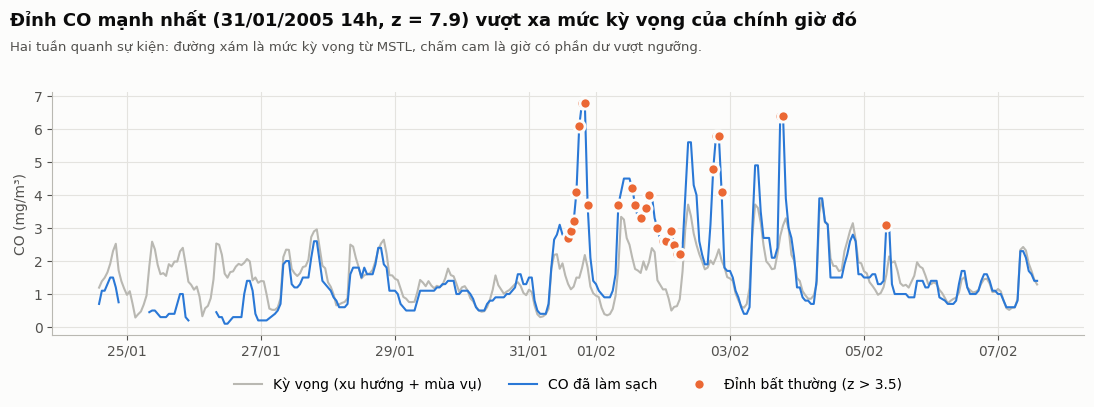

In [10]:
c = "CO(GT)"
top = events[events.pollutant == c].iloc[0]
win = slice(top.start - pd.Timedelta(days=7), top.start + pd.Timedelta(days=7))
expected = np.expm1(dec[c].trend + dec[c].seasonal.sum(axis=1))
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(expected.loc[win].index, expected.loc[win], color=NEUTRAL, lw=1.5, label="Kỳ vọng (xu hướng + mùa vụ)")
ax.plot(smooth.loc[win, c].index, smooth.loc[win, c], color=PALETTE[0], lw=1.5, label="CO đã làm sạch")
sp = smooth.loc[win, c][spike.loc[win, c]]
ax.plot(sp.index, sp, "o", ms=8, mfc=PALETTE[1], mec="#fcfcfb", mew=2, label=f"Đỉnh bất thường (z > {Z_THR})")
ax.set_ylabel(f"CO ({UNIT[c]})")
ax.xaxis.set_major_formatter(DateFormatter("%d/%m"))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
finish(fig, "06_spikes_example.png",
       f"Đỉnh CO mạnh nhất ({top.start:%d/%m/%Y %Hh}, z = {top.peak_z:.1f}) vượt xa mức kỳ vọng của chính giờ đó",
       "Hai tuần quanh sự kiện: đường xám là mức kỳ vọng từ MSTL, chấm cam là giờ có phần dư vượt ngưỡng.")

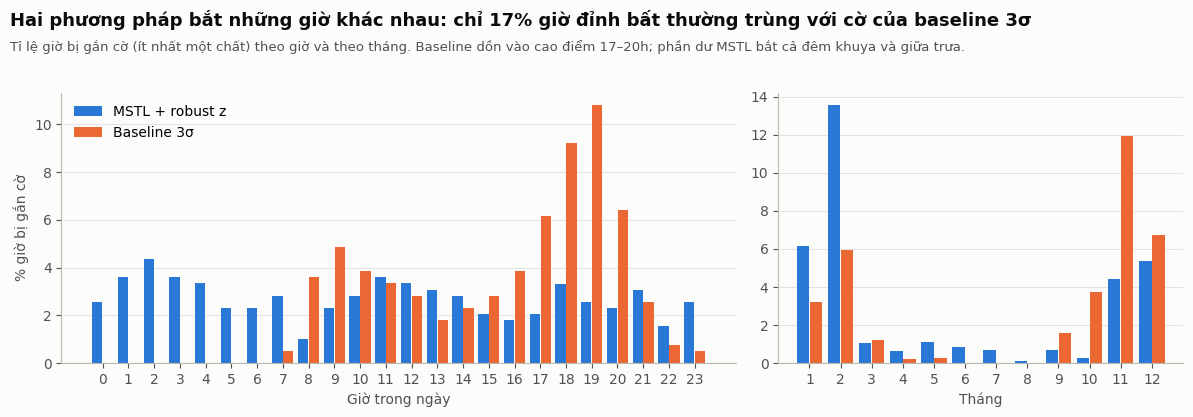

In [11]:
any_spike = spike.any(axis=1)
any_base = base_flag.any(axis=1)
obs_any = observed[POLL].any(axis=1)
by_hour = pd.DataFrame({"MSTL + robust z": any_spike[obs_any].groupby(idx[obs_any].hour).mean() * 100,
                        "Baseline 3σ": any_base[obs_any].groupby(idx[obs_any].hour).mean() * 100})
by_month = pd.DataFrame({"MSTL + robust z": any_spike[obs_any].groupby(idx[obs_any].month).mean() * 100,
                         "Baseline 3σ": any_base[obs_any].groupby(idx[obs_any].month).mean() * 100})
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [2, 1.2]})
for ax, tab, lab in [(axes[0], by_hour, "Giờ trong ngày"), (axes[1], by_month, "Tháng")]:
    x = np.arange(len(tab))
    ax.bar(x - 0.21, tab.iloc[:, 0], 0.4, color=PALETTE[0], label=tab.columns[0])
    ax.bar(x + 0.21, tab.iloc[:, 1], 0.4, color=PALETTE[1], label=tab.columns[1])
    ax.set_xticks(x, tab.index)
    ax.set_xlabel(lab)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("% giờ bị gắn cờ")
axes[0].legend(loc="upper left")
cold = idx.month.isin([10, 11, 12, 1, 2])
winter_share_base = any_base[cold].sum() / any_base.sum()
winter_share_mstl = any_spike[cold].sum() / any_spike.sum()
SUMMARY["winter_share"] = {"baseline": round(float(winter_share_base), 3), "mstl": round(float(winter_share_mstl), 3)}
overlap = (spike & base_flag).sum().sum() / spike.sum().sum()
SUMMARY["overlap_with_baseline"] = round(float(overlap), 3)
finish(fig, "07_spike_timing.png",
       f"Hai phương pháp bắt những giờ khác nhau: chỉ {overlap:.0%} giờ đỉnh bất thường trùng với cờ của baseline 3σ",
       "Tỉ lệ giờ bị gắn cờ (ít nhất một chất) theo giờ và theo tháng. Baseline dồn vào cao điểm 17–20h; phần dư MSTL bắt cả đêm khuya và giữa trưa.")

## 5. Bất thường đa biến (Isolation Forest)

Isolation Forest chạy trên vector phần dư z của 4 chất tại mỗi giờ. Nó bắt được những giờ mà **tổ hợp** các chất bất thường (ví dụ CO vọt lên nhưng NOx lại giảm — dấu hiệu lỗi cảm biến hoặc nguồn thải khác giao thông), kể cả các giờ thấp bất thường mà bộ phát hiện đơn biến (chỉ chiều dương) bỏ qua. `contamination = 0,02` (≈ 2% giờ).

{'flagged': 142, 'share_also_spike': 0.437, 'share_dip_only': 0.563, 'jaccard': 0.201}


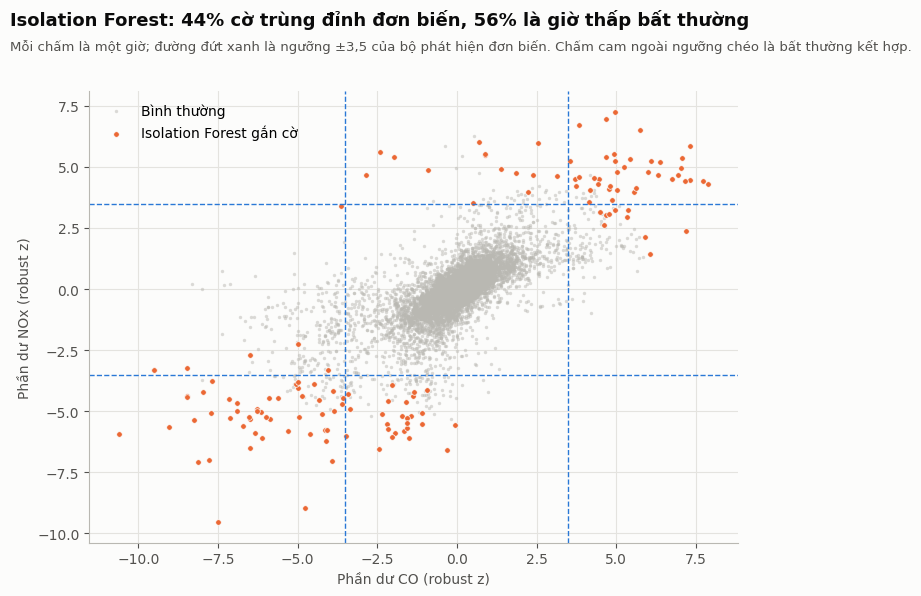

In [12]:
rows_ok = observed[POLL].all(axis=1) & inner  # cùng tập giờ với bộ đơn biến (bỏ biên MSTL)
Xif = Z.loc[rows_ok, POLL]
iso = IsolationForest(n_estimators=300, contamination=0.02, random_state=SEED).fit(Xif)
if_flag = pd.Series(iso.predict(Xif) == -1, index=Xif.index)
uni = spike.loc[Xif.index].any(axis=1)
dip = (Xif < -Z_THR).any(axis=1)
jac = (if_flag & uni).sum() / (if_flag | uni).sum()
share_uni = (if_flag & uni).sum() / if_flag.sum()
share_dip = (if_flag & dip & ~uni).sum() / if_flag.sum()
SUMMARY["iforest"] = {"flagged": int(if_flag.sum()), "share_also_spike": round(float(share_uni), 3),
                      "share_dip_only": round(float(share_dip), 3), "jaccard": round(float(jac), 3)}
print(SUMMARY["iforest"])

fig, ax = plt.subplots(figsize=(7.5, 6))
ax.scatter(Xif.loc[~if_flag, "CO(GT)"], Xif.loc[~if_flag, "NOx(GT)"], s=6, color=NEUTRAL, alpha=0.5, lw=0, label="Bình thường")
ax.scatter(Xif.loc[if_flag, "CO(GT)"], Xif.loc[if_flag, "NOx(GT)"], s=16, color=PALETTE[1], edgecolor="#fcfcfb", lw=0.5,
           label="Isolation Forest gắn cờ")
for v in (-Z_THR, Z_THR):
    ax.axvline(v, color=PALETTE[0], lw=1, ls="--")
    ax.axhline(v, color=PALETTE[0], lw=1, ls="--")
ax.set_xlabel("Phần dư CO (robust z)")
ax.set_ylabel("Phần dư NOx (robust z)")
ax.legend(loc="upper left")
finish(fig, "08_iforest.png",
       f"Isolation Forest: {share_uni:.0%} cờ trùng đỉnh đơn biến, {share_dip:.0%} là giờ thấp bất thường",
       "Mỗi chấm là một giờ; đường đứt xanh là ngưỡng ±3,5 của bộ phát hiện đơn biến. Chấm cam ngoài ngưỡng chéo là bất thường kết hợp.")

## 6. Mẫu ô nhiễm theo giờ, thứ và tháng

Heatmap trung bình theo (giờ × thứ) và (giờ × tháng) cho CO (chất sơ cấp từ xe) và NO2 (chất thứ cấp, hình thành sau phản ứng của NO). Thang màu tuần tự một sắc độ: đậm hơn = ô nhiễm hơn.

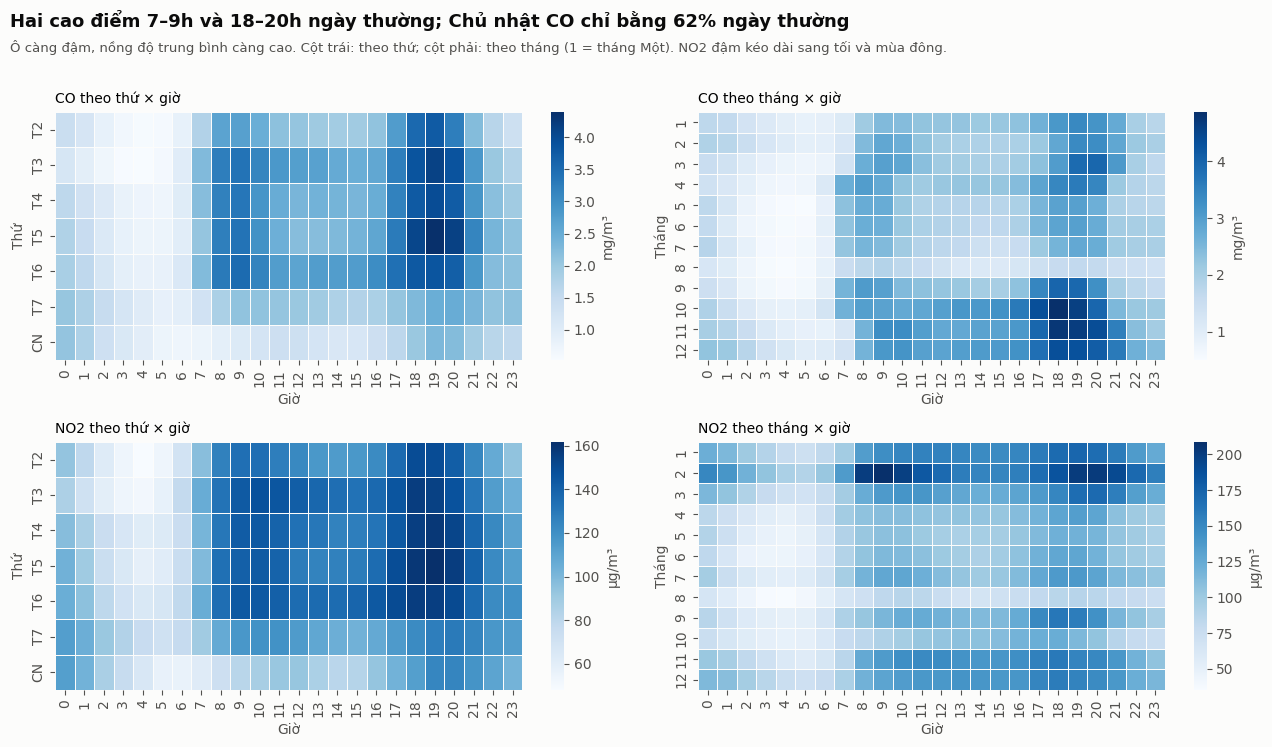

In [13]:
obs_smooth = smooth[POLL].where(observed[POLL])
DOW = ["T2", "T3", "T4", "T5", "T6", "T7", "CN"]
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
for row, c in enumerate(["CO(GT)", "NO2(GT)"]):
    hw = obs_smooth[c].groupby([idx.dayofweek, idx.hour]).mean().unstack()
    hw.index = DOW
    hm = obs_smooth[c].groupby([idx.month, idx.hour]).mean().unstack()
    for ax, tab, ylab in [(axes[row, 0], hw, "Thứ"), (axes[row, 1], hm, "Tháng")]:
        sns.heatmap(tab, cmap="Blues", ax=ax, cbar_kws={"label": UNIT[c]}, linewidths=0.5, linecolor="#fcfcfb")
        ax.set_title(f"{c.replace('(GT)', '')} theo {ylab.lower()} × giờ", loc="left", fontsize=10)
        ax.set_xlabel("Giờ")
        ax.set_ylabel(ylab)
        ax.grid(False)
co_hw = obs_smooth["CO(GT)"].groupby([idx.dayofweek, idx.hour]).mean().unstack()
sun_ratio = co_hw.loc[6].mean() / co_hw.loc[:4].mean().mean()
SUMMARY["co_sunday_vs_weekday"] = round(float(sun_ratio), 2)
finish(fig, "09_heatmaps.png",
       f"Hai cao điểm 7–9h và 18–20h ngày thường; Chủ nhật CO chỉ bằng {sun_ratio:.0%} ngày thường",
       "Ô càng đậm, nồng độ trung bình càng cao. Cột trái: theo thứ; cột phải: theo tháng (1 = tháng Một). NO2 đậm kéo dài sang tối và mùa đông.")

## 7. Khai phá mẫu tuần tự (PrefixSpan)

**Mã hóa:** mỗi ngày đủ số đo được chia thành 5 khung giờ — 00–05h, 06–09h (cao điểm sáng), 10–15h, 16–20h (cao điểm chiều), 21–23h. Chỉ số ô nhiễm tổng hợp = trung bình z-score của 4 chất; mỗi khung được gán mức **H** (tam phân vị trên) / **M** / **L** (tam phân vị dưới). Mỗi ngày trở thành một chuỗi theo thứ tự thời gian, chỉ giữ phần tử H và L (M là trạng thái trung tính), ví dụ `06–09h:H → 16–20h:H → 21–23h:H`.

**Khai phá:** PrefixSpan (closed patterns, độ dài ≥ 2, min support 15% số ngày). Với mỗi mẫu, tính **confidence** của luật tuần tự “tiền tố → phần tử cuối” và support riêng theo mùa / ngày thường–cuối tuần.

In [14]:
BLOCKS = [(0, 5, "00–05h"), (6, 9, "06–09h"), (10, 15, "10–15h"), (16, 20, "16–20h"), (21, 23, "21–23h")]
hour_block = {h: lab for a, b, lab in BLOCKS for h in range(a, b + 1)}
SEASON = {12: "Đông", 1: "Đông", 2: "Đông", 3: "Xuân", 4: "Xuân", 5: "Xuân",
          6: "Hè", 7: "Hè", 8: "Hè", 9: "Thu", 10: "Thu", 11: "Thu"}

zs = (smooth[POLL] - smooth[POLL].mean()) / smooth[POLL].std()
day = idx.normalize()
obs_all = observed[POLL].all(axis=1)
day_ok = obs_all.groupby(day).agg(["all", "size"])
complete_days = day_ok.index[(day_ok["all"]) & (day_ok["size"] == 24)]
SUMMARY["complete_days"] = len(complete_days)

pidx = zs.mean(axis=1)[np.isin(day, complete_days)]
blk = pidx.groupby([pidx.index.normalize(), pidx.index.hour.map(hour_block)]).mean().unstack()[[b[2] for b in BLOCKS]]
level = pd.qcut(blk.stack(), 3, labels=["L", "M", "H"]).unstack()[blk.columns]
seqs = {d: [f"{b}:{level.loc[d, b]}" for b in blk.columns if level.loc[d, b] != "M"] for d in blk.index}
db = list(seqs.values())

ps = PrefixSpan(db)
ps.minlen = 2
MINSUP = int(0.15 * len(db))
found = sorted(ps.frequent(MINSUP, closed=True), key=lambda t: -t[0])


def contains(seq: list[str], pat: list[str]) -> bool:
    it = iter(seq)
    return all(any(x == p for x in it) for p in pat)


assert all(sum(contains(s, p) for s in db) == sup for sup, p in found[:20])


def support(pat: list[str], days) -> float:
    return np.mean([contains(seqs[d], pat) for d in days]) * 100


groups = {"Ngày thường": [d for d in blk.index if d.dayofweek < 5],
          "Cuối tuần": [d for d in blk.index if d.dayofweek >= 5]}
for s in ["Xuân", "Hè", "Thu", "Đông"]:
    groups[s] = [d for d in blk.index if SEASON[d.month] == s]
rows = []
for sup, p in found[:15]:
    prefix_sup = sum(contains(s, p[:-1]) for s in db)
    row = {"pattern": " → ".join(p), "support_%": round(sup / len(db) * 100, 1),
           "confidence_%": round(sup / prefix_sup * 100, 1)}
    row.update({g: round(support(p, ds), 1) for g, ds in groups.items()})
    rows.append(row)
patterns = pd.DataFrame(rows)
patterns.to_csv(FIG / "patterns.csv", index=False)
SUMMARY["n_patterns"] = len(found)
SUMMARY["group_days"] = {g: len(v) for g, v in groups.items()}
SUMMARY["top_patterns"] = patterns.head(8).to_dict(orient="records")
print(f"{len(db)} ngày, {len(found)} mẫu closed (min support {MINSUP} ngày)")
patterns

279 ngày, 21 mẫu closed (min support 41 ngày)


,pattern,support_%,confidence_%,Ngày thường,Cuối tuần,Xuân,Hè,Thu,Đông
0,00–05h:L → 16–20h:H,47.3,58.7,63.2,11.6,45.3,42.4,62.1,41.8
1,10–15h:H → 16–20h:H,37.3,92.9,46.6,16.3,27.4,11.9,62.1,52.2
2,06–09h:H → 16–20h:H,30.5,86.7,43.0,2.3,24.2,20.3,50.0,31.3
3,00–05h:L → 10–15h:H,28.3,35.1,37.8,7.0,26.3,11.9,48.3,28.4
4,00–05h:L → 10–15h:H → 16–20h:H,26.2,92.4,35.8,4.7,23.2,11.9,44.8,26.9
5,00–05h:L → 06–09h:L,25.4,31.6,12.4,54.7,28.4,39.0,15.5,17.9
6,16–20h:H → 21–23h:H,25.1,40.7,30.6,12.8,23.2,5.1,25.9,44.8
7,06–09h:H → 10–15h:H,25.1,71.4,34.7,3.5,17.9,6.8,48.3,31.3
8,00–05h:L → 06–09h:H,24.7,30.7,35.8,0.0,25.3,23.7,37.9,13.4
9,06–09h:H → 10–15h:H → 16–20h:H,22.9,91.4,32.1,2.3,14.7,6.8,44.8,29.9


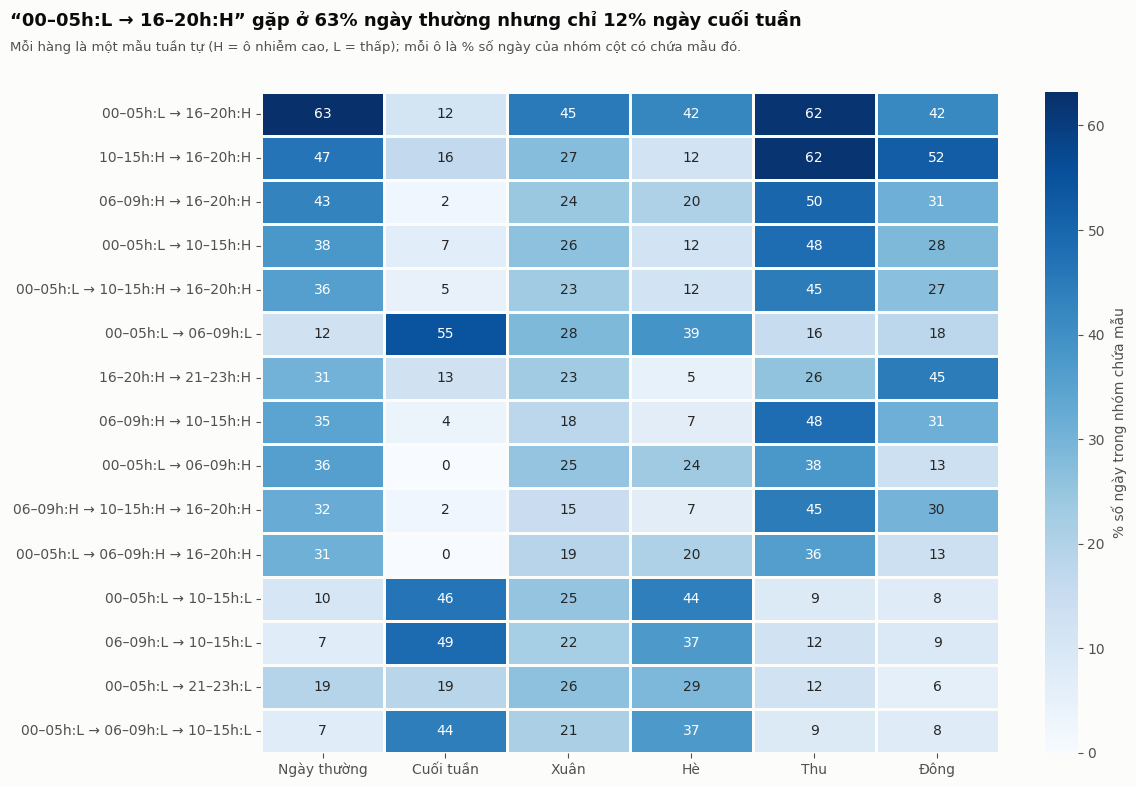

In [15]:
heat = patterns.set_index("pattern")[list(groups)]
fig, ax = plt.subplots(figsize=(12, 0.42 * len(heat) + 1.6))
sns.heatmap(heat, cmap="Blues", annot=True, fmt=".0f", cbar_kws={"label": "% số ngày trong nhóm chứa mẫu"},
            linewidths=1, linecolor="#fcfcfb", ax=ax)
ax.set_ylabel("")
ax.set_xlabel("")
ax.grid(False)
gap = (patterns["Ngày thường"] - patterns["Cuối tuần"]).where(patterns.pattern.str.contains(":H"))
top_h = patterns.loc[gap.idxmax()]
finish(fig, "10_sequence_patterns.png",
       f"“{top_h.pattern}” gặp ở {top_h['Ngày thường']:.0f}% ngày thường nhưng chỉ {top_h['Cuối tuần']:.0f}% ngày cuối tuần",
       "Mỗi hàng là một mẫu tuần tự (H = ô nhiễm cao, L = thấp); mỗi ô là % số ngày của nhóm cột có chứa mẫu đó.")

## 8. Phân cụm hồ sơ ô nhiễm theo ngày

**Vì sao phân cụm ngày thay cho trạm:** bộ dữ liệu UCI chỉ có **một** thiết bị đo, nên không thể nhóm các trạm. Thay vào đó, mỗi **ngày** được xem như một “trạm ảo” với hồ sơ ô nhiễm 24 giờ × 4 chất = 96 chiều (z-score theo từng chất, giữ cả **mức** lẫn **hình dạng** đường cong). Bài toán tương đương: nhóm các đơn vị có hồ sơ ô nhiễm giống nhau.

Quy trình: PCA giữ 90% phương sai → kiểm tra xu hướng cụm (Hopkins) → chọn k bằng Silhouette ↑ và Davies–Bouldin ↓ → so sánh K-Means, Agglomerative (Ward) và Hybrid (tâm Ward khởi tạo K-Means) → kiểm tra độ ổn định → mô tả cụm.

In [16]:
tmp = zs.loc[np.isin(day, complete_days), POLL].copy()
tmp["date"] = tmp.index.normalize()
tmp["hour"] = tmp.index.hour
X = tmp.pivot_table(index="date", columns="hour", values=POLL)
assert X.shape == (len(complete_days), 96) and X.notna().all().all()
pca = PCA(n_components=0.9, random_state=SEED).fit(X)
Xp = pca.transform(X)
SUMMARY["pca_dims"] = int(pca.n_components_)


def hopkins(data: np.ndarray, frac: float, rng: np.random.Generator) -> float:
    n = len(data)
    m = max(1, int(frac * n))
    nn = NearestNeighbors(n_neighbors=2).fit(data)
    w = nn.kneighbors(data[rng.choice(n, m, replace=False)], 2)[0][:, 1]
    u = nn.kneighbors(rng.uniform(data.min(0), data.max(0), (m, data.shape[1])), 1)[0][:, 0]
    return float(u.sum() / (u.sum() + w.sum()))


rng = np.random.default_rng(SEED)
H = np.mean([hopkins(Xp, 0.1, rng) for _ in range(20)])
H_rand = np.mean([hopkins(rng.uniform(Xp.min(0), Xp.max(0), Xp.shape), 0.1, rng) for _ in range(20)])
SUMMARY["hopkins"] = [round(float(H), 3), round(float(H_rand), 3)]
print(f"{X.shape[0]} ngày × {X.shape[1]} chiều → PCA {pca.n_components_} chiều; Hopkins = {H:.3f} (ngẫu nhiên ≈ {H_rand:.3f})")

279 ngày × 96 chiều → PCA 8 chiều; Hopkins = 0.724 (ngẫu nhiên ≈ 0.499)


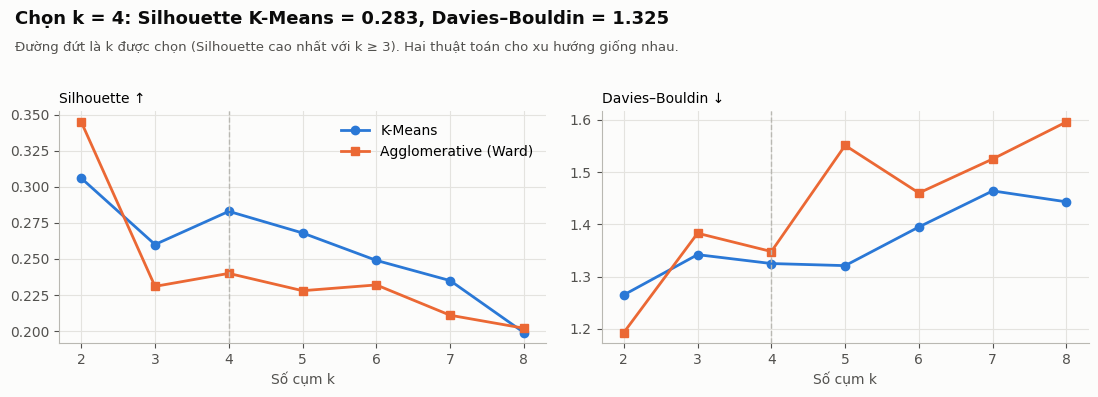

,sil_kmeans,db_kmeans,sil_ward,db_ward
k,,,,
2,0.306,1.265,0.345,1.193
3,0.260,1.342,0.231,1.383
4,0.283,1.325,0.240,1.348
5,0.268,1.321,0.228,1.551
6,0.249,1.395,0.232,1.460
7,0.235,1.464,0.211,1.525
8,0.199,1.443,0.202,1.596


In [17]:
KS = range(2, 9)
scores = []
for k in KS:
    km = KMeans(k, n_init=20, random_state=SEED).fit_predict(Xp)
    wd = AgglomerativeClustering(k, linkage="ward").fit_predict(Xp)
    scores.append({"k": k, "sil_kmeans": silhouette_score(Xp, km), "db_kmeans": davies_bouldin_score(Xp, km),
                   "sil_ward": silhouette_score(Xp, wd), "db_ward": davies_bouldin_score(Xp, wd)})
scores = pd.DataFrame(scores).set_index("k").round(3)
# Chọn k: Silhouette K-Means cao nhất trong k >= 3 (k = 2 chỉ tách "ngày sạch / ngày bẩn", không đủ cho mô tả hồ sơ).
K = int(scores.loc[3:, "sil_kmeans"].idxmax())
SUMMARY["k_scores"] = scores.to_dict(orient="index")
SUMMARY["K"] = K

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, m, lab in [(axes[0], "sil", "Silhouette ↑"), (axes[1], "db", "Davies–Bouldin ↓")]:
    ax.plot(scores.index, scores[f"{m}_kmeans"], color=PALETTE[0], marker="o", label="K-Means")
    ax.plot(scores.index, scores[f"{m}_ward"], color=PALETTE[1], marker="s", label="Agglomerative (Ward)")
    ax.axvline(K, color=NEUTRAL, ls="--", lw=1)
    ax.set_xlabel("Số cụm k")
    ax.set_title(lab, loc="left", fontsize=10)
axes[0].legend(loc="upper right")
finish(fig, "11_choose_k.png",
       f"Chọn k = {K}: Silhouette K-Means = {scores.loc[K, 'sil_kmeans']:.3f}, Davies–Bouldin = {scores.loc[K, 'db_kmeans']:.3f}",
       "Đường đứt là k được chọn (Silhouette cao nhất với k ≥ 3). Hai thuật toán cho xu hướng giống nhau.")
scores

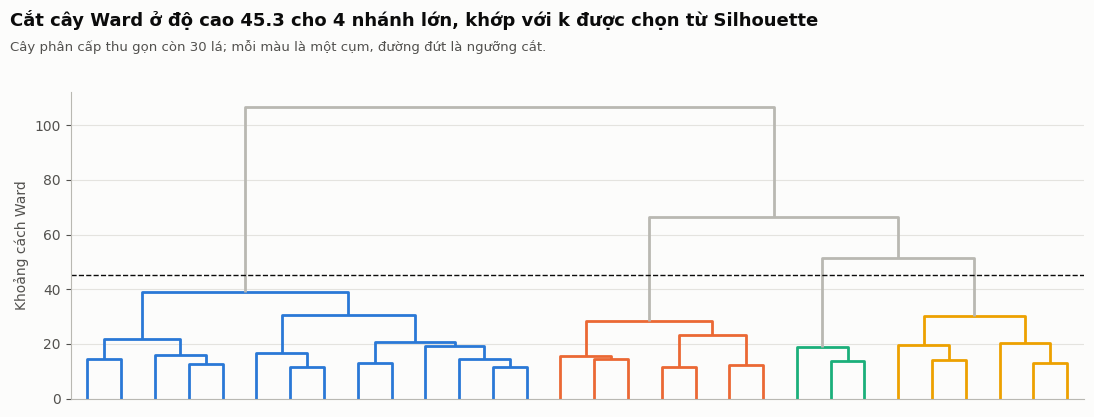

In [18]:
Lw = linkage(Xp, method="ward")
cut = (Lw[-K, 2] + Lw[-K + 1, 2]) / 2
set_link_color_palette(PALETTE[:K])
fig, ax = plt.subplots(figsize=(11, 4.2))
dendrogram(Lw, truncate_mode="lastp", p=30, color_threshold=cut, above_threshold_color=NEUTRAL, ax=ax, no_labels=True)
ax.axhline(cut, color=INK, ls="--", lw=1)
ax.set_ylabel("Khoảng cách Ward")
ax.grid(axis="x", visible=False)
finish(fig, "12_dendrogram.png",
       f"Cắt cây Ward ở độ cao {cut:.1f} cho {K} nhánh lớn, khớp với k được chọn từ Silhouette",
       "Cây phân cấp thu gọn còn 30 lá; mỗi màu là một cụm, đường đứt là ngưỡng cắt.")

In [19]:
km = KMeans(K, n_init=20, random_state=SEED).fit(Xp)
wd = AgglomerativeClustering(K, linkage="ward").fit_predict(Xp)
centers = np.vstack([Xp[wd == j].mean(0) for j in range(K)])
hy = KMeans(K, init=centers, n_init=1, random_state=SEED).fit(Xp)
methods = {"K-Means++ (n_init=20)": km.labels_, "Agglomerative (Ward)": wd, "Hybrid (Ward → K-Means)": hy.labels_}
evaluation = pd.DataFrame([{
    "method": name, "silhouette": silhouette_score(Xp, lab), "davies_bouldin": davies_bouldin_score(Xp, lab),
    "calinski_harabasz": calinski_harabasz_score(Xp, lab), "ARI_vs_KMeans": adjusted_rand_score(km.labels_, lab),
} for name, lab in methods.items()]).round(3)
evaluation.to_csv(FIG / "evaluation.csv", index=False)
SUMMARY["evaluation"] = evaluation.to_dict(orient="records")
evaluation

,method,silhouette,davies_bouldin,calinski_harabasz,ARI_vs_KMeans
0,K-Means++ (n_init=20),0.283,1.325,124.078,1.000
1,Agglomerative (Ward),0.240,1.348,108.394,0.527
2,Hybrid (Ward → K-Means),0.274,1.261,121.423,0.731


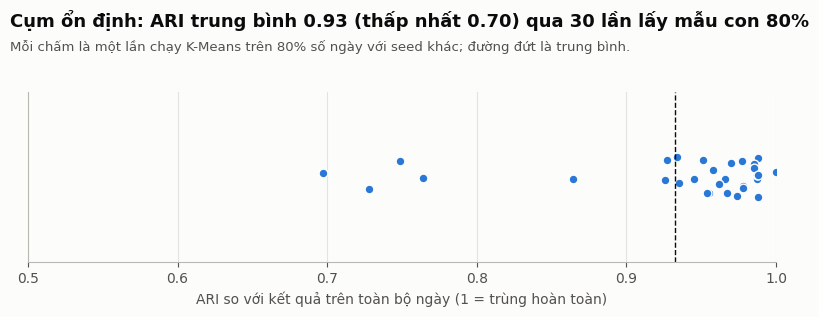

In [20]:
# Ổn định: 30 lần lấy mẫu con 80% + seed khác → ARI so với nhãn gốc trên cùng các ngày.
rng = np.random.default_rng(SEED)
stab = []
for i in range(30):
    sub = rng.choice(len(Xp), int(0.8 * len(Xp)), replace=False)
    lab_sub = KMeans(K, n_init=20, random_state=SEED + i + 1).fit_predict(Xp[sub])
    stab.append({"run": i, "ARI": adjusted_rand_score(km.labels_[sub], lab_sub)})
stab = pd.DataFrame(stab).round(3)
stab.to_csv(FIG / "stability.csv", index=False)
SUMMARY["stability"] = {"mean": round(float(stab.ARI.mean()), 3), "min": round(float(stab.ARI.min()), 3)}

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.scatter(stab.ARI, rng.uniform(-0.15, 0.15, len(stab)), s=40, color=PALETTE[0], edgecolor="#fcfcfb", lw=1)
ax.axvline(stab.ARI.mean(), color=INK, lw=1, ls="--")
ax.set_ylim(-0.6, 0.6)
ax.set_yticks([])
ax.set_xlim(min(0.5, stab.ARI.min() - 0.05), 1.0)
ax.set_xlabel("ARI so với kết quả trên toàn bộ ngày (1 = trùng hoàn toàn)")
finish(fig, "13_stability.png",
       f"Cụm ổn định: ARI trung bình {stab.ARI.mean():.2f} (thấp nhất {stab.ARI.min():.2f}) qua 30 lần lấy mẫu con 80%",
       "Mỗi chấm là một lần chạy K-Means trên 80% số ngày với seed khác; đường đứt là trung bình.")

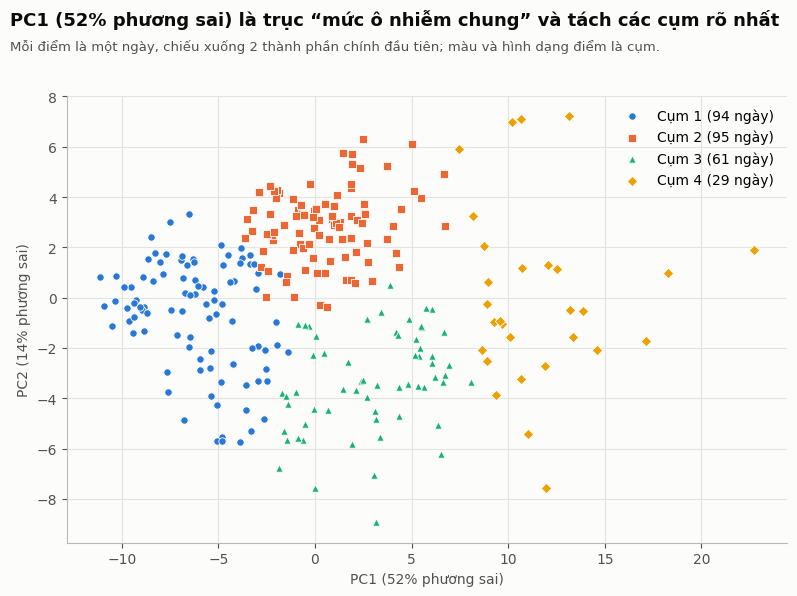

In [21]:
# Đánh số lại cụm theo mức ô nhiễm trung bình tăng dần: Cụm 1 = sạch nhất.
raw_lab = pd.Series(km.labels_, index=X.index)
order = X.mean(axis=1).groupby(raw_lab).mean().sort_values().index
relabel = {old: new for new, old in enumerate(order, start=1)}
lab = raw_lab.map(relabel)
CCOLOR = {k: PALETTE[k - 1] for k in range(1, K + 1)}
MARK = ["o", "s", "^", "D", "v", "P", "X", "*"]

fig, ax = plt.subplots(figsize=(8, 6))
for k in range(1, K + 1):
    m = (lab == k).to_numpy()
    ax.scatter(Xp[m, 0], Xp[m, 1], s=28, marker=MARK[k - 1], color=CCOLOR[k], edgecolor="#fcfcfb", lw=0.6,
               label=f"Cụm {k} ({m.sum()} ngày)")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} phương sai)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} phương sai)")
ax.legend(loc="best")
finish(fig, "14_pca_clusters.png",
       f"PC1 ({pca.explained_variance_ratio_[0]:.0%} phương sai) là trục “mức ô nhiễm chung” và tách các cụm rõ nhất",
       "Mỗi điểm là một ngày, chiếu xuống 2 thành phần chính đầu tiên; màu và hình dạng điểm là cụm.")

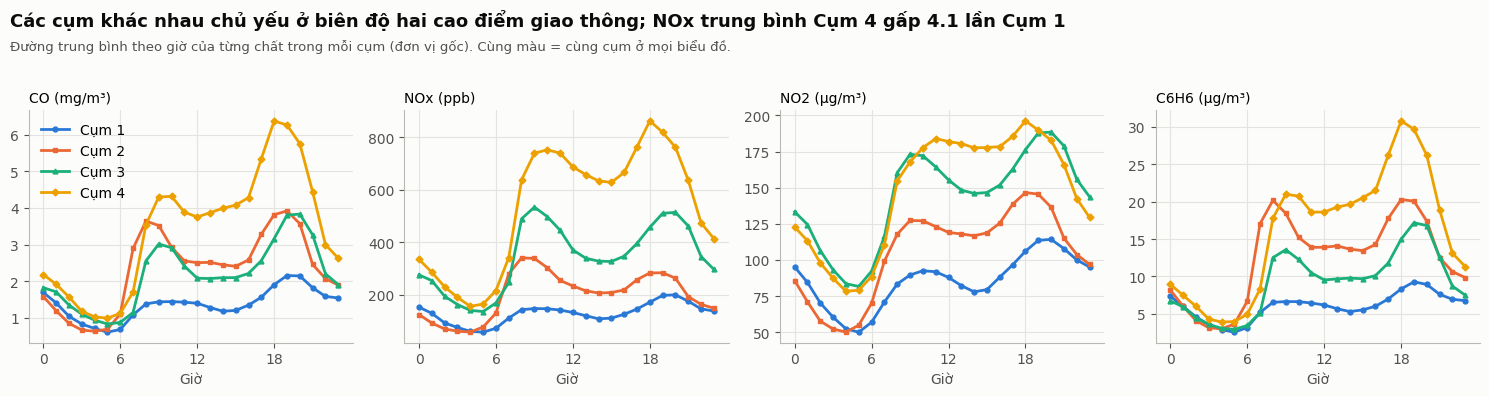

In [22]:
units = smooth.loc[np.isin(day, X.index), POLL].copy()
units["cluster"] = lab.reindex(units.index.normalize()).to_numpy()
units["hour"] = units.index.hour
fig, axes = plt.subplots(1, 4, figsize=(15, 4), sharex=True)
for ax, c in zip(axes, POLL):
    prof = units.groupby(["cluster", "hour"])[c].mean().unstack(0)
    for k in prof:
        ax.plot(prof.index, prof[k], color=CCOLOR[k], marker=MARK[k - 1], ms=3.5, label=f"Cụm {k}")
    ax.set_title(f"{c.replace('(GT)', '')} ({UNIT[c]})", loc="left", fontsize=10)
    ax.set_xticks(range(0, 24, 6))
    ax.set_xlabel("Giờ")
axes[0].legend(loc="upper left")
nox = units.groupby("cluster")["NOx(GT)"].mean()
finish(fig, "15_cluster_profiles.png",
       f"Các cụm khác nhau chủ yếu ở biên độ hai cao điểm giao thông; NOx trung bình Cụm {K} gấp {nox[K] / nox[1]:.1f} lần Cụm 1",
       "Đường trung bình theo giờ của từng chất trong mỗi cụm (đơn vị gốc). Cùng màu = cùng cụm ở mọi biểu đồ.")

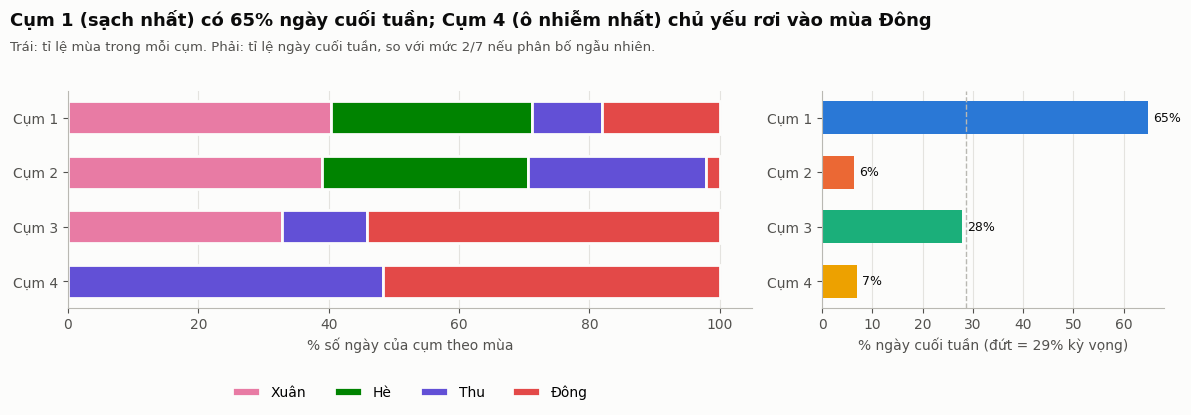

,n_days,share_%,weekend_%,top_season,spike_hours_per_day,CO(GT),NOx(GT),NO2(GT),C6H6(GT),T,RH,AH
cluster,,,,,,,,,,,,
1,94,33.7,64.9,Xuân,0.22,1.37,128.89,85.29,6.04,19.00,46.43,1.02
2,95,34.1,6.3,Xuân,0.23,2.32,199.78,104.89,12.39,22.16,47.43,1.18
3,61,21.9,27.9,Đông,1.21,2.17,342.96,143.46,9.27,10.53,52.32,0.66
4,29,10.4,6.9,Đông,3.31,3.40,532.71,147.93,15.91,11.64,61.67,0.88


In [23]:
meta = pd.DataFrame(index=X.index)
meta["cluster"] = lab
meta["weekend"] = meta.index.dayofweek >= 5
meta["season"] = meta.index.month.map(SEASON)
daily = smooth[POLL + MET].groupby(day).mean().reindex(meta.index)
spk_day = spike.any(axis=1).groupby(day).sum().reindex(meta.index)
profile = pd.DataFrame({
    "n_days": meta.groupby("cluster").size(),
    "share_%": (meta.groupby("cluster").size() / len(meta) * 100).round(1),
    "weekend_%": (meta.groupby("cluster").weekend.mean() * 100).round(1),
    "top_season": meta.groupby("cluster").season.agg(lambda s: s.value_counts().idxmax()),
    "spike_hours_per_day": spk_day.groupby(meta.cluster).mean().round(2),
}).join(daily.groupby(meta.cluster).mean().round(2))
profile.to_csv(FIG / "cluster_profile.csv")
SUMMARY["cluster_profile"] = profile.reset_index().to_dict(orient="records")

seasons = ["Xuân", "Hè", "Thu", "Đông"]
comp = pd.crosstab(meta.cluster, meta.season, normalize="index").reindex(columns=seasons, fill_value=0) * 100
fig, axes = plt.subplots(1, 2, figsize=(12, 0.6 * K + 2.2), gridspec_kw={"width_ratios": [2, 1]})
left = np.zeros(K)
for i, s in enumerate(seasons):
    # Mùa dùng slot 5-8 để không trùng màu cụm (slot 1-4).
    axes[0].barh([f"Cụm {k}" for k in comp.index], comp[s], left=left, color=PALETTE[4 + i], edgecolor="#fcfcfb",
                 lw=2, height=0.6, label=s)
    left += comp[s].to_numpy()
axes[0].set_xlabel("% số ngày của cụm theo mùa")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=4)
axes[0].invert_yaxis()
axes[1].barh([f"Cụm {k}" for k in profile.index], profile["weekend_%"], color=[CCOLOR[k] for k in profile.index], height=0.6)
for y, v in enumerate(profile["weekend_%"]):
    axes[1].text(v + 1, y, f"{v:.0f}%", va="center", fontsize=9, color=INK)
axes[1].axvline(2 / 7 * 100, color=NEUTRAL, ls="--", lw=1)
axes[1].set_xlabel("% ngày cuối tuần (đứt = 29% kỳ vọng)")
axes[1].invert_yaxis()
for ax in axes:
    ax.grid(axis="y", visible=False)
finish(fig, "16_cluster_composition.png",
       f"Cụm 1 (sạch nhất) có {profile.loc[1, 'weekend_%']:.0f}% ngày cuối tuần; Cụm {K} (ô nhiễm nhất) chủ yếu rơi vào mùa {profile.loc[K, 'top_season']}",
       "Trái: tỉ lệ mùa trong mỗi cụm. Phải: tỉ lệ ngày cuối tuần, so với mức 2/7 nếu phân bố ngẫu nhiên.")
profile

## 9. Tóm tắt kết quả

Ô dưới in toàn bộ số liệu chính và lưu vào `reports/figures/summary.json` — `README.md` và `reports/REPORT.md` lấy số liệu từ file này.

In [24]:
outputs = sorted(p.name for p in FIG.iterdir() if p.suffix in {".png", ".csv"})
SUMMARY["outputs"] = outputs
(FIG / "summary.json").write_text(json.dumps(SUMMARY, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print(f"{sum(o.endswith('.png') for o in outputs)} biểu đồ, {sum(o.endswith('.csv') for o in outputs)} bảng CSV")
print(json.dumps({k: v for k, v in SUMMARY.items() if k not in {"top_patterns", "cluster_profile", "k_scores", "outputs"}},
                 ensure_ascii=False, indent=1, default=str))

16 biểu đồ, 6 bảng CSV
{
 "n_hours": 9357,
 "period": "10/03/2004 – 04/04/2005",
 "missing_pct": {
  "PT08.S1(CO)": 3.9,
  "C6H6(GT)": 3.9,
  "PT08.S2(NMHC)": 3.9,
  "PT08.S3(NOx)": 3.9,
  "PT08.S4(NO2)": 3.9,
  "PT08.S5(O3)": 3.9,
  "T": 3.9,
  "RH": 3.9,
  "AH": 3.9,
  "NOx(GT)": 17.5,
  "NO2(GT)": 17.5,
  "CO(GT)": 18.0,
  "NMHC(GT)": 90.2
 },
 "preprocess": {
  "CO(GT)": {
   "% thiếu gốc": 18.0,
   "% nội suy ngắn": 2.0,
   "% còn thiếu (khoảng dài)": 16.0
  },
  "NOx(GT)": {
   "% thiếu gốc": 17.5,
   "% nội suy ngắn": 3.5,
   "% còn thiếu (khoảng dài)": 14.0
  },
  "NO2(GT)": {
   "% thiếu gốc": 17.5,
   "% nội suy ngắn": 3.5,
   "% còn thiếu (khoảng dài)": 14.1
  },
  "C6H6(GT)": {
   "% thiếu gốc": 3.9,
   "% nội suy ngắn": 0.2,
   "% còn thiếu (khoảng dài)": 3.8
  },
  "T": {
   "% thiếu gốc": 3.9,
   "% nội suy ngắn": 0.2,
   "% còn thiếu (khoảng dài)": 3.8
  },
  "RH": {
   "% thiếu gốc": 3.9,
   "% nội suy ngắn": 0.2,
   "% còn thiếu (khoảng dài)": 3.8
  },
  "AH": {
   "%